# Proyecto 2 — Simulación Monte Carlo de precios

**La pregunta:** si invierto hoy en SPY, ¿cuánto tendré dentro de un año?

**La respuesta honesta:** nadie lo sabe. Pero sí se puede responder una pregunta mejor: *¿cuál es el rango de resultados posibles, y con qué probabilidad?*

Eso es **Monte Carlo**: en lugar de una predicción, generamos miles de futuros posibles que sean consistentes con cómo se ha comportado el activo en el pasado, y miramos la distribución. Es la herramienta base de gestión de riesgo, pricing de derivados y planificación de portafolios.

**Cómo funciona un notebook de este repo:** texto con la teoría → celda de código → "Qué mirar". Tú lees; el código lo ejecutas con Shift+Enter o `Run → Run All Cells`.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from quantlab import (load_prices, log_returns, simple_returns, estimate_params,
                      simulate_gbm, simulate_bootstrap, simulate_correlated_gbm,
                      value_at_risk, conditional_var)

plt.rcParams["figure.figsize"] = (12, 5)
sns.set_theme(style="whitegrid")

prices = load_prices(["SPY", "TLT", "GLD", "TSLA"], start="2019-01-01")
lrets = log_returns(prices)

## 1. El modelo: movimiento browniano geométrico (GBM)

Necesitamos una regla que diga cómo se mueve el precio cada día. La más usada en finanzas es el **GBM**. En palabras:

> El precio de mañana = el precio de hoy × un factor aleatorio.
> Ese factor tiene una parte **esperada** (la tendencia, llamada *drift* o $\mu$) y una parte **aleatoria** (un "shock" diario cuyo tamaño típico es la volatilidad $\sigma$).

En fórmula, para un día:

$$S_{t+1} = S_t \cdot \exp\Big( (\mu - \tfrac{\sigma^2}{2})\,dt + \sigma \sqrt{dt}\, Z \Big), \qquad Z \sim N(0,1)$$

Traducción pieza por pieza:
- $S_t$: precio hoy. $dt = 1/252$: un día como fracción de año.
- $\mu$: retorno esperado anual (ej. 0.10 = 10%). Sale del histórico.
- $\sigma$: volatilidad anual (ej. 0.20 = 20%). Sale del histórico.
- $Z$: un número al azar de una campana de Gauss centrada en 0. Cada día, cada trayectoria, uno nuevo. **Aquí está todo el azar.**
- $-\sigma^2/2$: una corrección técnica; sin ella, promediar exponenciales infla el resultado. Ignórala salvo que quieras el detalle.

**Lo importante:** GBM solo necesita dos números del pasado, $\mu$ y $\sigma$, y asume que los shocks diarios son normales e independientes. Esa última suposición es su gran debilidad, y la vamos a exponer en la sección 4.

In [2]:
mu, sigma = estimate_params(lrets["SPY"])
s0 = prices["SPY"].iloc[-1]
print(f"SPY hoy: {s0:.2f}   mu anual: {mu:.1%}   sigma anual: {sigma:.1%}")

SPY hoy: 765.41   mu anual: 16.0%   sigma anual: 19.3%


## 2. Simular 10.000 futuros

Con esos dos números generamos 10.000 trayectorias de 252 días (un año hábil). Cada trayectoria es un "universo paralelo" posible.

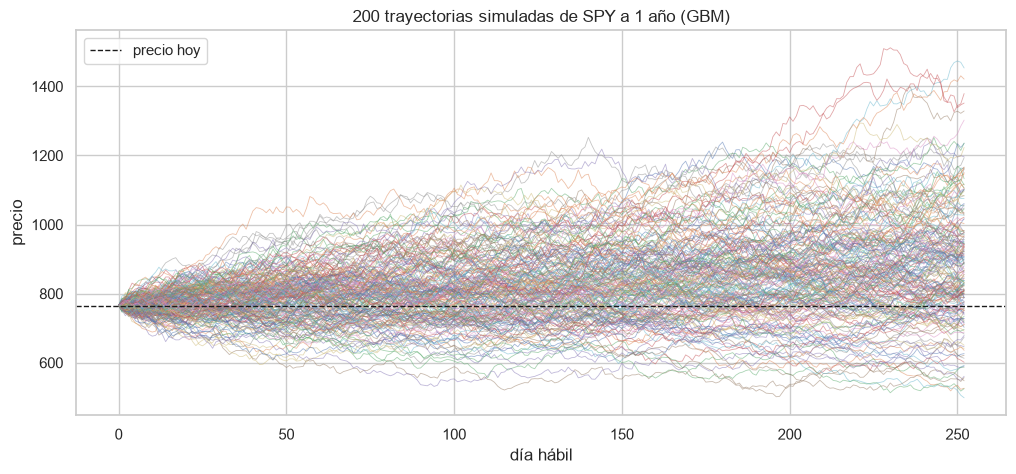

In [3]:
N_PATHS, N_DAYS = 10_000, 252
paths = simulate_gbm(s0, mu, sigma, n_days=N_DAYS, n_paths=N_PATHS)

fig, ax = plt.subplots()
ax.plot(paths[:, :200], lw=0.6, alpha=0.5)          # 200 de las 10.000, por legibilidad
ax.axhline(s0, color="k", ls="--", lw=1, label="precio hoy")
ax.set_title("200 trayectorias simuladas de SPY a 1 año (GBM)")
ax.set_xlabel("día hábil"); ax.set_ylabel("precio"); ax.legend()
plt.show()

**Qué mirar:** el abanico se abre con el tiempo. La incertidumbre crece con la raíz del tiempo, no linealmente: a 4 años la dispersión es 2x la de 1 año, no 4x. Ninguna trayectoria individual significa nada; lo que importa es el conjunto.

## 3. La distribución de resultados a un año

Tomamos el precio final de cada trayectoria, lo convertimos a retorno (% respecto a hoy) y miramos la forma de la distribución.

Dos medidas de riesgo estándar en la industria:
- **VaR al 95%** (*Value at Risk*): "en el 95% de los escenarios NO pierdo más que X". Es el percentil 5 de los retornos. Todo banco lo reporta.
- **CVaR** (*Conditional VaR* o *Expected Shortfall*): "en el 5% de escenarios malos, ¿cuánto pierdo en promedio?". El VaR te dice dónde empieza el desastre; el CVaR cuánto de desastre.

Percentil  5%: -16.4%   (VaR 95%)
Percentil 25%: +1.4%
Mediana      : +15.3%
Percentil 75%: +31.6%
Percentil 95%: +58.7%
CVaR 95%     : -22.6%   (pérdida media en el peor 5%)
P(perder dinero): 22.7%


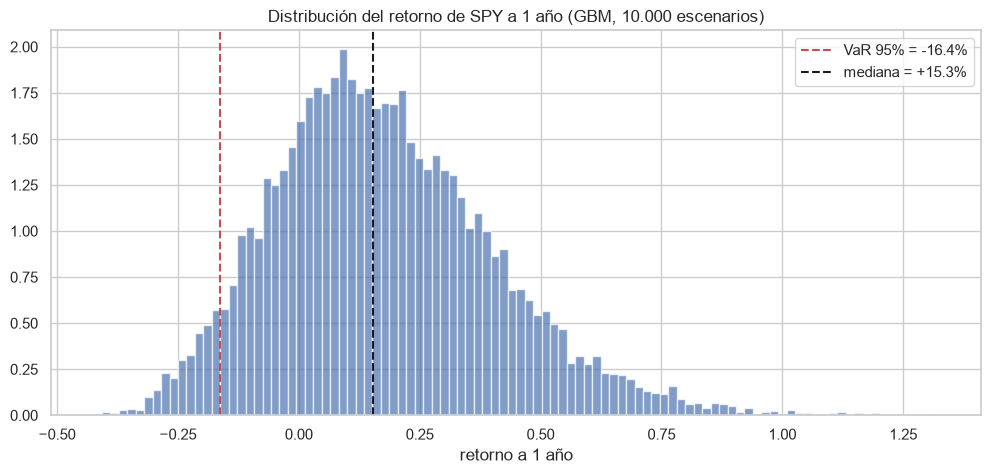

In [4]:
final_rets = paths[-1] / s0 - 1

pct = np.percentile(final_rets, [5, 25, 50, 75, 95])
var95, cvar95 = value_at_risk(final_rets), conditional_var(final_rets)

print(f"Percentil  5%: {pct[0]:+.1%}   (VaR 95%)")
print(f"Percentil 25%: {pct[1]:+.1%}")
print(f"Mediana      : {pct[2]:+.1%}")
print(f"Percentil 75%: {pct[3]:+.1%}")
print(f"Percentil 95%: {pct[4]:+.1%}")
print(f"CVaR 95%     : {cvar95:+.1%}   (pérdida media en el peor 5%)")
print(f"P(perder dinero): {(final_rets < 0).mean():.1%}")

plt.hist(final_rets, bins=100, density=True, alpha=0.7)
plt.axvline(var95, color="r", ls="--", label=f"VaR 95% = {var95:+.1%}")
plt.axvline(pct[2], color="k", ls="--", label=f"mediana = {pct[2]:+.1%}")
plt.title("Distribución del retorno de SPY a 1 año (GBM, 10.000 escenarios)")
plt.xlabel("retorno a 1 año"); plt.legend()
plt.show()

**Qué mirar:** la distribución es asimétrica a la derecha: puedes ganar más de 100% pero no perder más de 100%. La probabilidad de perder dinero en un año en SPY es ~25-30%: invertir en el mercado un solo año es una apuesta bastante incierta; es a 10-20 años cuando la tendencia domina al ruido.

**Aviso:** estos números dependen de $\mu$, y $\mu$ estimado con 7 años de datos es muy ruidoso. Si el período incluye un mercado alcista fuerte, el modelo será optimista. Los quants desconfían del $\mu$ histórico; de $\sigma$ se fían mucho más.

## 4. El problema del GBM: colas gordas

En el Proyecto 1 vimos que los retornos reales tienen **curtosis** alta: los días extremos ocurren mucho más de lo que la campana de Gauss predice. El GBM usa shocks normales, así que **fabrica un mundo sin días extremos**. Comprobémoslo.

In [5]:
sim_daily = np.diff(np.log(paths), axis=0).ravel()
real_daily = lrets["SPY"]

print(f"Curtosis retornos diarios reales   : {real_daily.kurtosis():.1f}")
print(f"Curtosis retornos diarios simulados: {stats.kurtosis(sim_daily):.1f}")
print(f"Peor día real     : {real_daily.min():.1%}")
print(f"Peor día simulado : {sim_daily.min():.1%}  (entre {len(sim_daily):,} días simulados)")

Curtosis retornos diarios reales   : 14.4
Curtosis retornos diarios simulados: 0.0
Peor día real     : -11.6%
Peor día simulado : -6.1%  (entre 2,520,000 días simulados)


**Qué mirar:** la curtosis real es ~10+; la simulada, ~0. Y el peor día que el GBM "imagina" en millones de días es más suave que lo que SPY ha hecho en la realidad. El modelo subestima sistemáticamente el riesgo de cola: este es exactamente el error detrás de 2008 (modelos que decían "esto es un evento de una vez cada 10.000 años" ocurriendo tres días seguidos).

### Alternativa: bootstrap histórico

En vez de inventar shocks normales, **remuestreamos días reales**: cada día futuro se copia al azar de un día del pasado. Si en el histórico hubo un -11%, puede volver a salir. Conserva las colas gordas sin ninguna fórmula.

In [6]:
paths_bs = simulate_bootstrap(s0, lrets["SPY"], n_days=N_DAYS, n_paths=N_PATHS)
final_bs = paths_bs[-1] / s0 - 1

comp = pd.DataFrame({
    "GBM (normal)": [np.median(final_rets), value_at_risk(final_rets), conditional_var(final_rets), (final_rets < -0.20).mean()],
    "Bootstrap (días reales)": [np.median(final_bs), value_at_risk(final_bs), conditional_var(final_bs), (final_bs < -0.20).mean()],
}, index=["mediana", "VaR 95%", "CVaR 95%", "P(caída > 20%)"])
comp.style.format("{:+.1%}")

,GBM (normal),Bootstrap (días reales)
mediana,+15.3%,+17.0%
VaR 95%,-16.4%,-14.8%
CVaR 95%,-22.6%,-21.2%
P(caída > 20%),+3.1%,+2.4%


**Qué mirar:** el VaR suele parecerse, pero el CVaR y la probabilidad de una caída fuerte son peores en el bootstrap. Las diferencias son la "prima" que el GBM se estaba ahorrando por asumir normalidad.

El bootstrap tampoco es perfecto: al barajar los días pierde el **clustering de volatilidad** (en la realidad los días malos vienen en racha). Modelos como GARCH (Proyecto 3) arreglan eso. Lección quant general: **no existe el modelo correcto, solo modelos con errores conocidos**. Tu trabajo es saber cuál es el error de cada uno.

## 5. Simular un portafolio: activos correlacionados

Hasta ahora, un activo. Un portafolio real tiene varios, y **no puedes simularlos por separado**: si SPY y TSLA se mueven juntos (correlación 0.5), sus shocks diarios tienen que ir juntos también. Si los simulas independientes, inventas una diversificación que no existe y el riesgo te sale demasiado bajo.

**El truco (descomposición de Cholesky):** generas shocks independientes y los "mezclas" con una matriz sacada de la covarianza histórica, de modo que la mezcla tenga exactamente las correlaciones observadas. Es álgebra lineal de primer curso; en el código es una línea.

Vamos a comparar tres carteras a 1 año:
- 100% SPY
- 60% SPY / 40% TLT (la clásica "60/40")
- 40% SPY / 30% TLT / 30% GLD

In [7]:
assets = ["SPY", "TLT", "GLD"]
lr = lrets[assets]
mu_vec = np.array([estimate_params(lr[a])[0] for a in assets])
cov_daily = lr.cov().to_numpy()
s0_vec = prices[assets].iloc[-1].to_numpy()

paths_multi = simulate_correlated_gbm(s0_vec, mu_vec, cov_daily, n_days=N_DAYS, n_paths=N_PATHS)
asset_rets = paths_multi[-1] / s0_vec - 1          # (n_paths, 3): retorno a 1 año de cada activo

carteras = {"100% SPY": [1, 0, 0], "60/40 SPY/TLT": [0.6, 0.4, 0], "40/30/30 SPY/TLT/GLD": [0.4, 0.3, 0.3]}
rows = {}
for name, w in carteras.items():
    r = asset_rets @ np.array(w)
    rows[name] = {"mediana": np.median(r), "vol de resultados": r.std(),
                  "VaR 95%": value_at_risk(r), "CVaR 95%": conditional_var(r),
                  "P(perder)": (r < 0).mean()}
pd.DataFrame(rows).T.style.format("{:+.1%}")

,mediana,vol de resultados,VaR 95%,CVaR 95%,P(perder)
100% SPY,+15.3%,+22.8%,-16.4%,-22.4%,+23.3%
60/40 SPY/TLT,+8.5%,+14.3%,-12.2%,-16.4%,+26.0%
40/30/30 SPY/TLT/GLD,+10.7%,+12.7%,-8.0%,-12.4%,+18.4%


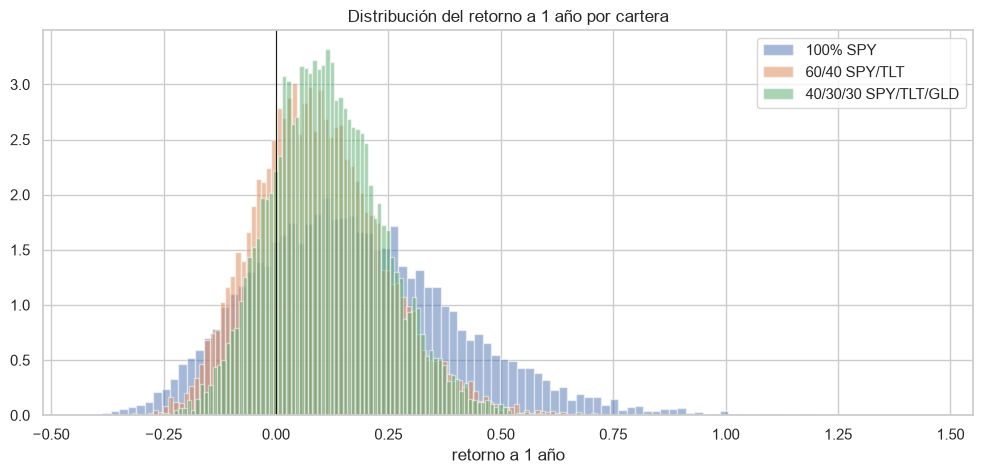

In [8]:
fig, ax = plt.subplots()
for name, w in carteras.items():
    ax.hist(asset_rets @ np.array(w), bins=100, alpha=0.5, density=True, label=name)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Distribución del retorno a 1 año por cartera")
ax.set_xlabel("retorno a 1 año"); ax.legend()
plt.show()

**Qué mirar:** al diversificar, la campana se estrecha: mediana algo menor, pero VaR y CVaR bastante mejores. Estás cambiando un poco de retorno esperado por mucha menos incertidumbre. Eso es exactamente lo que el Sharpe mide, y lo que la optimización de portafolios (Proyecto 6) hace de forma sistemática: buscar los pesos que dan la mejor distribución.

Y recuerda la advertencia del Proyecto 1: esta simulación usa la correlación histórica SPY/TLT como si fuera fija. En 2022 no lo fue. Un modelo así te habría dicho que el 60/40 estaba protegido justo antes de su peor año en décadas.

## 6. Para qué sirve esto en el mundo real

- **Gestión de riesgo:** todo banco calcula VaR diario de su cartera con alguna versión de esto, y el regulador le exige capital en función del resultado.
- **Pricing de derivados (Proyecto 5):** una opción es una apuesta sobre el precio futuro; su precio justo es el promedio del pago en miles de escenarios simulados. Mismo motor.
- **Planificación:** "¿cuánto necesito ahorrar al mes para tener X con 90% de probabilidad?" se responde con Monte Carlo, no con una regla de tres.
- **Test de estrategias (Proyecto 4):** si tu estrategia funcionó en el pasado, ¿fue habilidad o suerte? Se prueba contra miles de pasados alternativos simulados.

## 7. Preguntas (respóndelas sin buscar)

1. Un amigo te dice: "mi modelo predice que SPY estará en 620 dentro de un año". ¿Qué le responderías después de este notebook?
2. Si el VaR 95% de una cartera es -15% y el CVaR es -16%, ¿qué te dice sobre la forma de la cola? ¿Y si el VaR es -15% y el CVaR es -35%?
3. ¿Por qué simular SPY y TSLA como independientes daría un riesgo de cartera *menor* que el real?
4. ¿En qué se equivoca el GBM, en qué se equivoca el bootstrap, y por qué ninguno de los dos es "el correcto"?

Siguiente: Proyecto 3, series de tiempo. Vamos a mirar si el pasado dice algo del futuro (autocorrelación), qué significa que una serie sea "estacionaria", y a modelar la volatilidad cambiante con GARCH, arreglando el defecto que el bootstrap dejó.